In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

Matplotlib is building the font cache; this may take a moment.


In [2]:
# import the MNIST dataset and split it into training and validation sets
train = datasets.MNIST("data", train=True, download=True, transform=transforms.ToTensor())
test  = datasets.MNIST("data", train=False, download=True, transform=transforms.ToTensor())
gen = torch.Generator().manual_seed(0)
train_ds, val_ds = random_split(train, [50000, 10000], generator=gen)

In [3]:
batch_size = 512

In [4]:
train_dl, val_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True), DataLoader(val_ds, batch_size=batch_size)

In [5]:
# def loss_func(preds, trgts):
#     preds = preds.sigmoid()
#     trgts_array = torch.zeros_like(preds)
#     trgts_array[range(len(preds)), trgts] = 1
#     loss = (preds-trgts_array).abs()
#     return loss.mean()
loss_func = nn.CrossEntropyLoss()

In [6]:
def train_epoch(model, train_dl, loss_func, optimizer):
    model.train()
    losses = []
    for x,y in train_dl:
        x = x.view(x.size(0), -1)
        y = y.view(-1)
        preds = model(x)
        loss = loss_func(preds, y)
        losses.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return sum(losses)/len(losses)

In [7]:
def batch_accuracy(preds, trgts):
    preds = preds.argmax(dim=1)
    correct = preds == trgts
    return correct.float().mean()

In [8]:
def validate_epoch(model, val_dl):
    model.eval()
    with torch.no_grad():
        accs = []
        for x,y in val_dl:
            x = x.view(x.size(0), -1)
            y = y.view(-1)
            preds = model(x)
            acc = batch_accuracy(preds, y)
            accs.append(acc)
        return torch.stack(accs).mean()

In [9]:
def train_model(model, train_dl, val_dl, loss_func, optimizer, epochs):
    history = {"epoch": [], "loss": [], "acc": []}
    for epoch in range(epochs):
        loss = train_epoch(model, train_dl, loss_func, optimizer)
        acc = validate_epoch(model, val_dl)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}, Validation Accuracy: {acc:.4f}")
        history["loss"].append(loss)
        history["acc"].append(acc)
    return history

In [10]:
# model = nn.Linear(28*28, 10)

# model = nn.Sequential(
#     nn.Linear(28*28,30),
#     nn.ReLU(),
#     nn.Linear(30,10)
# )

model = nn.Sequential(
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 64),  nn.ReLU(),
    nn.Linear(64, 10)
    )


lr = .1
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

In [11]:
hist_ce = train_model(model=model, train_dl=train_dl, val_dl=val_dl, loss_func=loss_func, optimizer=optimizer, epochs=100)

Epoch 1/100, Loss: 2.1693, Validation Accuracy: 0.6014
Epoch 2/100, Loss: 0.9097, Validation Accuracy: 0.8069
Epoch 3/100, Loss: 0.4844, Validation Accuracy: 0.8750
Epoch 4/100, Loss: 0.3803, Validation Accuracy: 0.8999
Epoch 5/100, Loss: 0.3258, Validation Accuracy: 0.9032
Epoch 6/100, Loss: 0.2884, Validation Accuracy: 0.9201
Epoch 7/100, Loss: 0.2563, Validation Accuracy: 0.9288
Epoch 8/100, Loss: 0.2283, Validation Accuracy: 0.9325
Epoch 9/100, Loss: 0.2027, Validation Accuracy: 0.9418
Epoch 10/100, Loss: 0.1831, Validation Accuracy: 0.9443
Epoch 11/100, Loss: 0.1680, Validation Accuracy: 0.9508
Epoch 12/100, Loss: 0.1554, Validation Accuracy: 0.9531
Epoch 13/100, Loss: 0.1392, Validation Accuracy: 0.9541
Epoch 14/100, Loss: 0.1287, Validation Accuracy: 0.9584
Epoch 15/100, Loss: 0.1201, Validation Accuracy: 0.9586
Epoch 16/100, Loss: 0.1110, Validation Accuracy: 0.9622
Epoch 17/100, Loss: 0.1030, Validation Accuracy: 0.9628
Epoch 18/100, Loss: 0.0969, Validation Accuracy: 0.9632
E

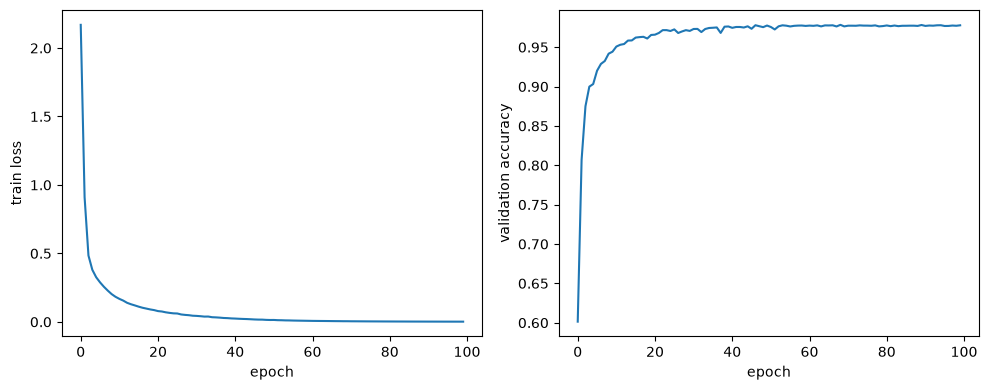

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
epochs, losses, accs = range(100), hist_ce['loss'], hist_ce['acc']
ax1.plot(epochs, losses); ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss")
ax2.plot(epochs, accs);   ax2.set_xlabel("epoch"); ax2.set_ylabel("validation accuracy")
plt.tight_layout(); plt.show()

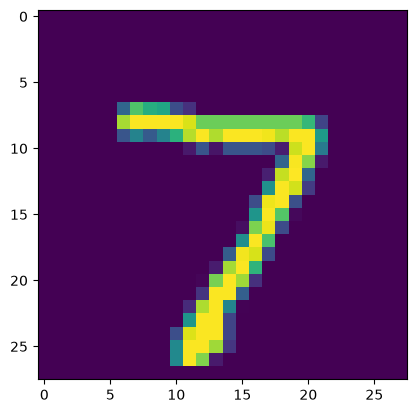

7


In [22]:
plt.imshow(a[0])
plt.show()
print(b)

In [32]:
def exact_accuracy(model, dl):
    model.eval()
    correct, n = 0, 0
    with torch.no_grad():
        for x, y in dl:
            x = x.view(x.size(0), -1)
            correct += (model(x).argmax(dim=1) == y).sum().item()
            n += len(y)
    return correct / n

In [33]:
exact_accuracy(model, test_dl)

0.9785

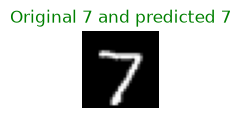

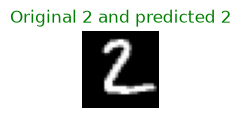

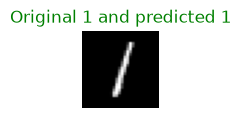

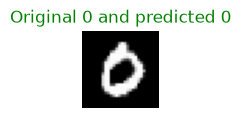

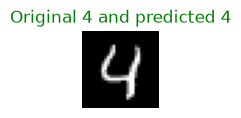

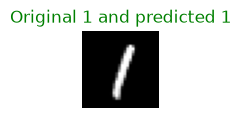

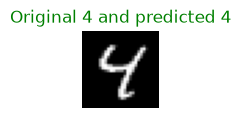

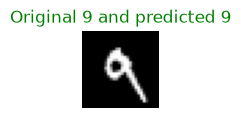

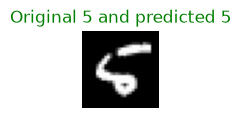

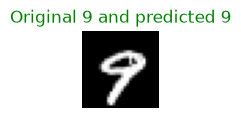

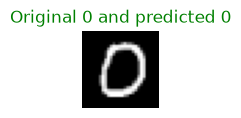

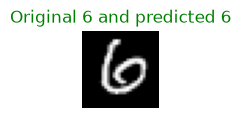

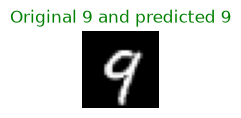

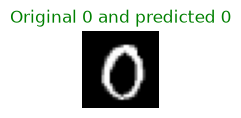

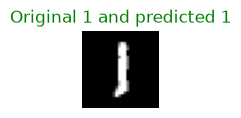

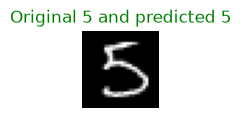

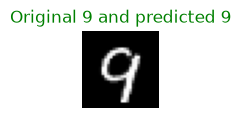

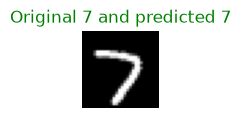

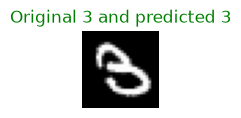

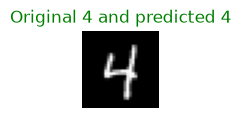

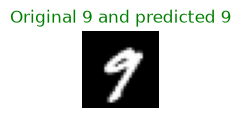

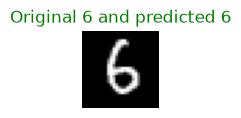

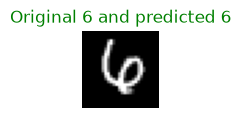

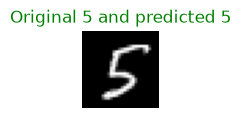

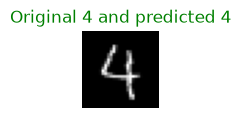

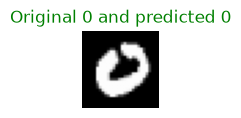

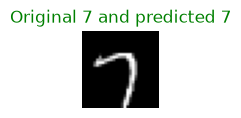

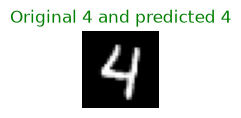

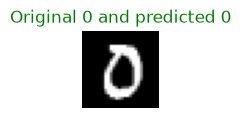

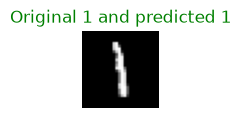

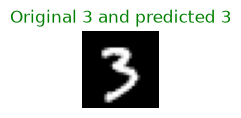

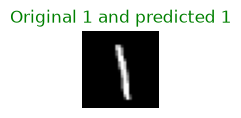

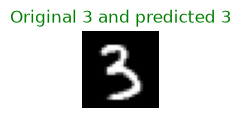

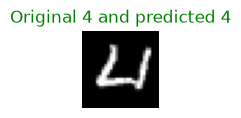

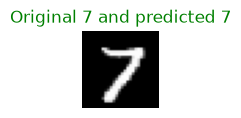

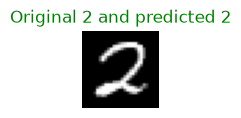

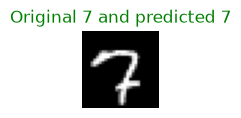

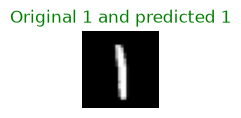

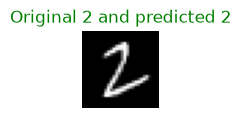

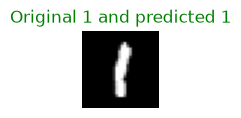

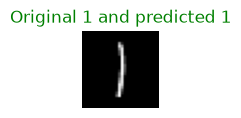

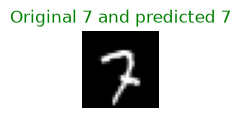

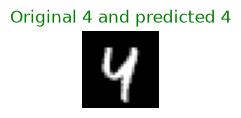

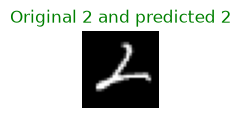

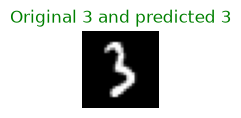

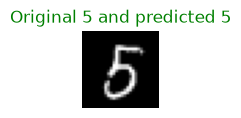

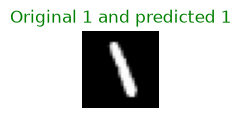

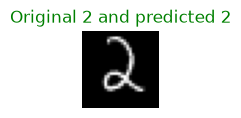

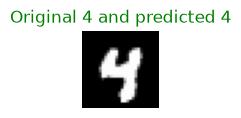

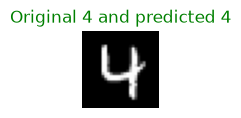

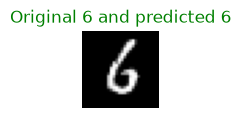

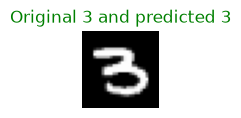

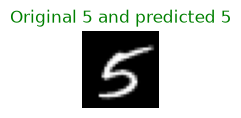

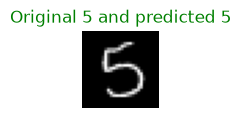

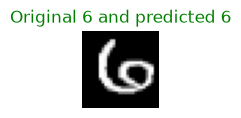

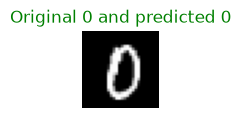

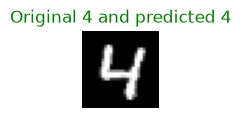

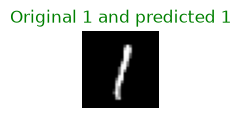

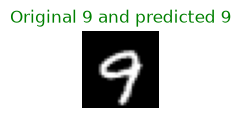

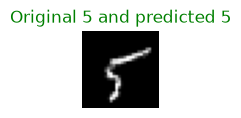

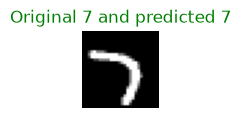

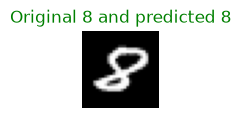

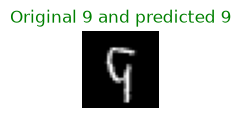

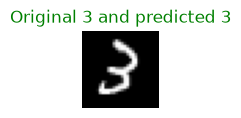

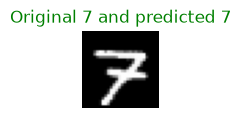

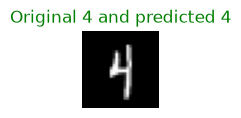

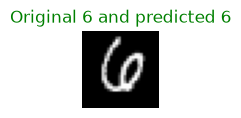

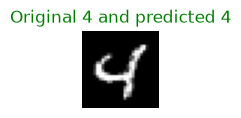

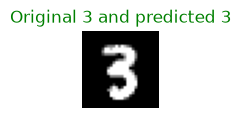

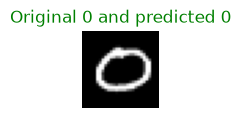

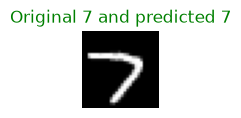

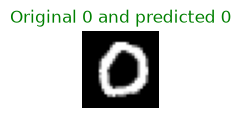

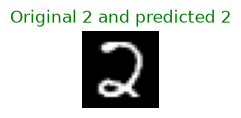

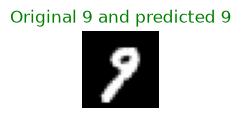

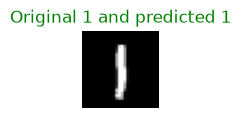

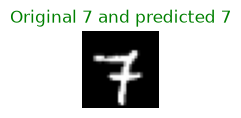

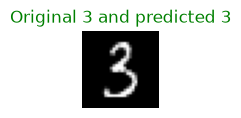

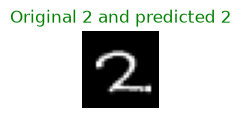

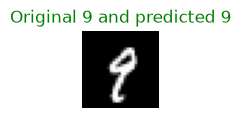

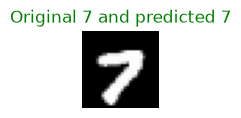

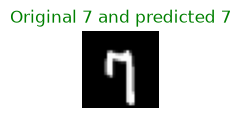

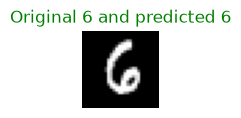

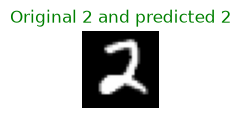

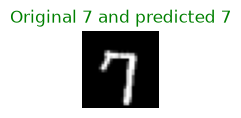

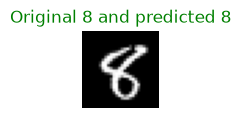

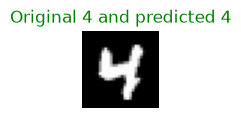

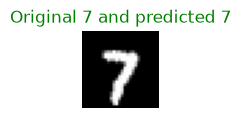

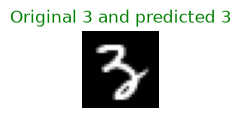

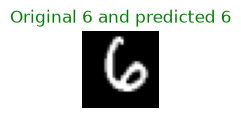

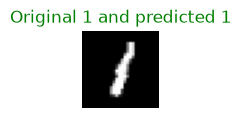

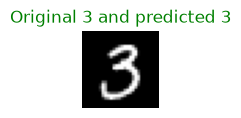

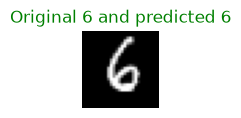

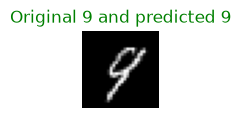

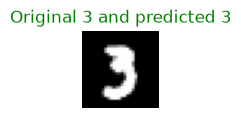

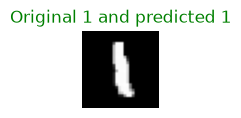

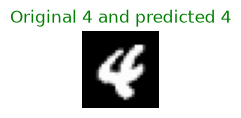

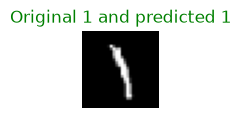

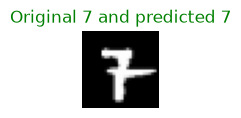

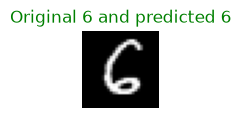

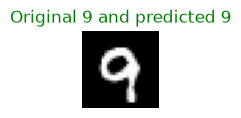

In [54]:
model.eval()
with torch.no_grad():
    for i in range(100):
        x, y = test[i]
        fig, ax = plt.subplots(figsize=[1,1])
        ax.imshow(x[0], cmap='grey')
        x = x.view(x.size(0), -1)
        pred = model(x).argmax(dim=1)
        correct = y == pred
        ax.set_title(f"Original {y} and predicted {int(pred)}", color = 'green' if correct else 'red')
        ax.set_axis_off()
        plt.show()